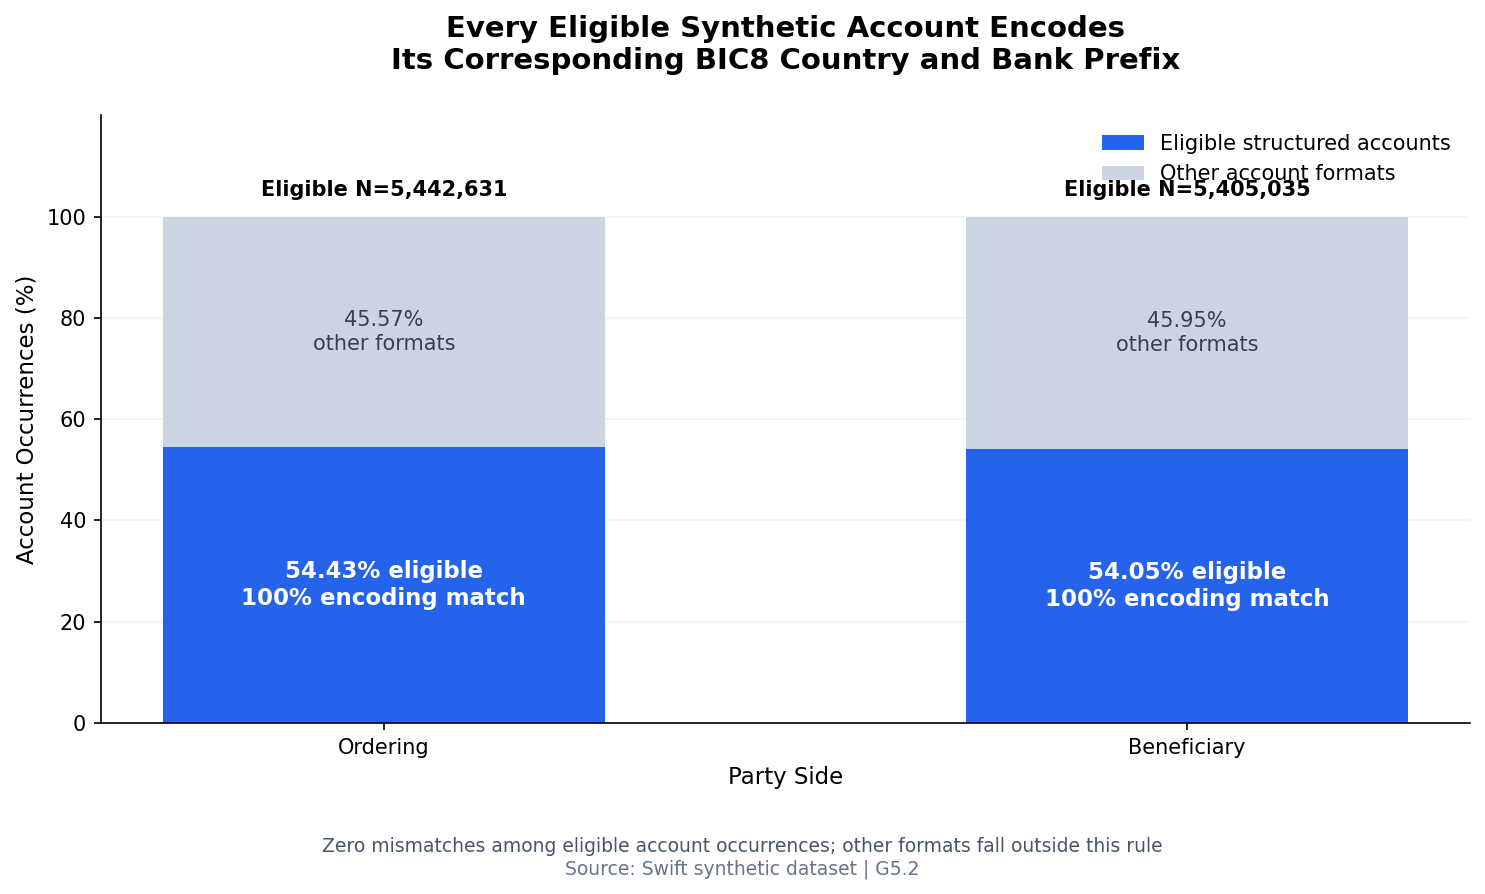

In [1]:

import matplotlib.pyplot as plt

# Person 2 verified data: Rule G5.2
# Counts refer to account-field occurrences

sides = ["Ordering", "Beneficiary"]

total = [10_000_000, 10_000_000]

# Accounts matching the synthetic IBAN-like pattern
eligible = [5_442_631, 5_405_035]

# Every eligible account matched its BIC8 encoding
verified_matches = [5_442_631, 5_405_035]

# Calculate percentages
eligible_rates = [
    e / t * 100
    for e, t in zip(eligible, total)
]

other_rates = [
    100 - rate
    for rate in eligible_rates
]

match_rates = [
    m / e * 100
    for m, e in zip(verified_matches, eligible)
]

# Create figure
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

colors = {
    "eligible": "#2563EB",
    "other": "#CBD5E1"
}

# First stacked section
ax.bar(
    sides,
    eligible_rates,
    color=colors["eligible"],
    width=0.55,
    label="Eligible structured accounts"
)

# Second stacked section
ax.bar(
    sides,
    other_rates,
    bottom=eligible_rates,
    color=colors["other"],
    width=0.55,
    label="Other account formats"
)

# Add labels inside bars
for i in range(len(sides)):

    ax.text(
        i,
        eligible_rates[i] / 2,
        f"{eligible_rates[i]:.2f}% eligible\n"
        f"{match_rates[i]:.0f}% encoding match",
        ha="center",
        va="center",
        fontsize=11,
        color="white",
        fontweight="bold"
    )

    ax.text(
        i,
        eligible_rates[i] + other_rates[i] / 2,
        f"{other_rates[i]:.2f}%\nother formats",
        ha="center",
        va="center",
        fontsize=10,
        color="#334155"
    )

    ax.text(
        i,
        104,
        f"Eligible N={eligible[i]:,}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Headline
ax.set_title(
    "Every Eligible Synthetic Account Encodes\n"
    "Its Corresponding BIC8 Country and Bank Prefix",
    fontsize=14,
    fontweight="bold",
    pad=22
)

ax.set_ylabel("Account Occurrences (%)", fontsize=11)
ax.set_xlabel("Party Side", fontsize=11)

ax.set_ylim(0, 120)
ax.set_yticks([0, 20, 40, 60, 80, 100])

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper right",
    frameon=False
)

# Evidence notes
fig.text(
    0.5, 0.045,
    "Zero mismatches among eligible account occurrences; "
    "other formats fall outside this rule",
    ha="center",
    fontsize=9,
    color="#475569"
)

fig.text(
    0.5, 0.02,
    "Source: Swift synthetic dataset | "
    "G5.2",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.09, 1, 1])

# Export 300 DPI chart
plt.savefig(
    "g5_account_encoding.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
